[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/limorigu/uchicago-python-ai-workshop/blob/main/notebooks/02_fcc_whitespace_STARTER.ipynb)

# 02 · Case study 1 — Whitespace analysis for Lakeshore Broadband

**Situation.** Lakeshore Broadband is an imaginary regional cable/fiber operator in northern Illinois (Lake, McHenry, Kane and part of Boone County). A sponsor is considering an investment and wants to know: *where could Lakeshore expand next, and how big is that opportunity?*

**Data.** A classroom extract shaped exactly like the FCC's **Broadband Data Collection (BDC)** fixed-availability download (one row per provider × location × technology), plus a location table, Lakeshore's current footprint, and illustrative county demographics. Everything you need is already loaded for you in Step 1.

> *Side note, not part of today's work:* if you ever want to go deeper after the workshop, the real BDC data — hundreds of millions of rows — is a free download at https://broadbandmap.fcc.gov/data-download, and this notebook's logic runs on it unchanged.

**Deliverable (individual, 45 min):** a ranked table of whitespace counties with units, revenue and payback, exported to Excel, plus one chart.
**Deliverable (group, 25 min):** stress-test the assumptions, choose a top-2 recommendation, and be ready to defend it in 2 minutes.

**It is completely fine to run out of time.** The steps are ordered so that whatever you finish is a coherent piece of analysis, and Part 2 starts from your table's most complete notebook — an unfinished Part 1 costs you nothing. Depth beats speed: better to understand four steps than to paste your way through seven.

**You have done every one of these moves today.** Steps 1–2 are Lab C; step 3 is Lab A (assumptions as named variables); steps 4–5 are the pivot/merge demo; step 6 is Lab B (dictionaries + functions). The case is assembly, not first contact.

**Using AI assistants.** You're welcome to ask an AI assistant (ChatGPT, Claude, Colab's built-in AI) about syntax or what a function does — but **try it yourself first**, and turn off inline code suggestions if you can (in Colab: Settings → AI Assistance), bringing them back only if you're really struggling and a chat on the side isn't enough. If you do use one: read every line it gives you until you can say why it's there, then prove you've retained it — write a *different but similar* line yourself (a new column, another grouping) without the assistant. If you can't, you didn't learn it yet; ask again until you can.

**Definitions this case uses.** These are *choices, not facts* — a different analyst could set different thresholds and get a different answer. In Part 2, your table will stress-test exactly these, so keep them in mind:
- *Served location*: at least one **terrestrial, low-latency, residential** offer at **≥100/20 Mbps**.
- *Competitors in a block*: distinct providers (other than Lakeshore) offering ≥100/20.
- *Whitespace block*: **not** in Lakeshore's footprint, in a county **adjacent** to it, with **≤1** competitor on average.

In [18]:
# --- Setup: get the workshop files into this Colab session ------------------------------
# Downloads the workshop repository (data + helper code). Takes ~10 seconds the first time.
import os, sys
REPO_URL = "https://github.com/limorigu/uchicago-python-ai-workshop"
if not any(os.path.exists(d) for d in ["workshop/data", "data", "../data"]):
    !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 $REPO_URL workshop
DATA = next((d for d in ["workshop/data", "data", "../data"] if os.path.exists(d)), None)
if DATA is None:
    raise RuntimeError("Could not download the workshop files. Check your internet connection and "
                       "that this link opens in your browser: " + REPO_URL + " . Still stuck? Email the instructor.")
sys.path.insert(0, "workshop/app" if os.path.exists("workshop/app") else "../app")
print("Data folder:", DATA, "| files:", sorted(os.listdir(DATA)))

Data folder: workshop/data | files: ['case1', 'case2']


## Step 1 — Load the four tables
Notice `dtype={...}`: codes like FRN and GEOID must stay text, or leading zeros vanish — the same bug as Excel turning a ZIP code into a number.

In [56]:
import pandas as pd, numpy as np
avail = pd.read_csv(f"{DATA}/case1/bdc_il_fixed_availability_sample.csv.gz", dtype={"frn": str, "block_geoid": str})
locs = pd.read_csv(f"{DATA}/case1/bdc_il_locations_sample.csv.gz", dtype={"block_geoid": str, "county_fips": str})
footprint = pd.read_csv(f"{DATA}/case1/lakeshore_footprint_blocks.csv", dtype={"block_geoid": str, "county_fips": str})
demo = pd.read_csv(f"{DATA}/case1/il_county_demographics_illustrative.csv", dtype={"county_fips": str})
tech = pd.read_csv(f"{DATA}/case1/bdc_technology_codes.csv")

EXCEL_ROW_LIMIT = 1_048_576
print(f"availability rows: {len(avail):,}  |  Excel row limit: {EXCEL_ROW_LIMIT:,}")
print(f"the full-scale version of this file (20x) would be ~{len(avail)*20:,} rows")
avail.head(3)

availability rows: 236,549  |  Excel row limit: 1,048,576
the full-scale version of this file (20x) would be ~4,730,980 rows


,frn,provider_id,brand_name,location_id,technology,max_advertised_download_speed,max_advertised_upload_speed,low_latency,business_residential_code,state_usps,block_geoid,h3_res8_id
0,0031200006,130006,OrbitNet,1000025989,60,100,12,0,R,IL,170310243001062,8819343707ffff
1,0031200006,130006,OrbitNet,1000015517,60,100,12,0,R,IL,170890343001118,8818964588ffff
2,0031200002,130002,Prairie Fiber,1000046910,50,2000,2000,1,R,IL,172010887001062,8823518080ffff


## Step 2 — Clean
Three hygiene steps that every real dataset needs: drop exact duplicates, normalise names, attach readable labels.

In [54]:
n0 = len(avail)
# TODO: drop exact duplicate rows                         -> avail = avail.drop_duplicates()
# TODO: normalise brand names (strip whitespace, title case), then fix the special cases
#       e.g. .replace({"Midstate Cable": "MidState Cable", "Heritagetel": "HeritageTel",
#                      "Skyreach Wireless": "SkyReach Wireless", "Orbitnet": "OrbitNet", "Starmesh": "StarMesh"})
# TODO: merge the technology names onto avail (left join on "technology")
print(f"dropped {n0-len(avail):,} duplicates; brands: {sorted(avail.brand_name.unique())}")

dropped 0 duplicates; brands: ['HERITAGETEL', 'HeritageTel', 'HeritageTel  ', 'LAKESHORE BROADBAND', 'Lakeshore Broadband', 'Lakeshore Broadband  ', 'MIDSTATE CABLE', 'MidState Cable', 'MidState Cable  ', 'ORBITNET', 'OrbitNet', 'OrbitNet  ', 'PRAIRIE FIBER', 'Prairie Fiber', 'Prairie Fiber  ', 'SKYREACH WIRELESS', 'STARMESH', 'SkyReach Wireless', 'SkyReach Wireless  ', 'StarMesh', 'StarMesh  ']


In [57]:
n0 = len(avail)
avail = avail.drop_duplicates()
print(f"dropped {n0-len(avail):,} duplicates")

avail["brand_name"] = avail["brand_name"].str.strip().str.title()

avail["brand_name"] = avail["brand_name"].replace({
    "Midstate Cable": "MidState Cable",
    "Heritagetel": "HeritageTel",
    "Skyreach Wireless": "SkyReach Wireless",
    "Orbitnet": "OrbitNet",
    "Starmesh": "StarMesh"
})
avail = avail.merge(tech, on="technology", how="left")

print(f"dropped {n0-len(avail):,} duplicates; brands: {sorted(avail.brand_name.unique())}")


dropped 2,342 duplicates
dropped 2,342 duplicates; brands: ['HeritageTel', 'Lakeshore Broadband', 'MidState Cable', 'OrbitNet', 'Prairie Fiber', 'SkyReach Wireless', 'StarMesh']


## Step 3 — Encode the definitions as parameters
Everything that is a *judgement* goes in a variable at the top. When the partner asks "what if we use 25/3 instead?" you change one line and re-run.

In [62]:
DOWN_MIN, UP_MIN = 100, 20          # 'served' threshold (BEAD uses 100/20; older FCC benchmark was 25/3)
SATELLITE = {60, 61}                # excluded from the terrestrial competition count — defend this choice!
OUR_BRAND = "Lakeshore Broadband"

# TODO: build three filtered frames
# res    = residential-capable offers: business_residential_code in ["R", "X"]
# terr   = res, excluding SATELLITE technologies and requiring low_latency == 1
# served = terr meeting BOTH speed thresholds
res = avail[avail["business_residential_code"].isin(["R", "X"])]

terr = res[
    (~res["technology"].isin(SATELLITE)) &
    (res["low_latency"] == 1)
]

served = terr[
    (terr["max_advertised_download_speed"] >= DOWN_MIN) &
    (terr["max_advertised_upload_speed"] >= UP_MIN)
]
print("Residential offers:", len(res))
print("Terrestrial offers:", len(terr))
print("Served offers:", len(served))


Residential offers: 222613
Terrestrial offers: 118965
Served offers: 69276


## Step 4 — Location level: who can each home buy from?
One row per location: number of distinct providers meeting the served definition, and whether *our brand* is one of them. This is a pivot table that Excel would need a helper column and COUNTIFS for; here it is one `groupby`.

**Name things for what they *mean*, not for today's parameter values.** Step 3 made the thresholds variables so you can change them in one place — so a column named `n_providers_100_20` would be a bug waiting to happen: change `DOWN_MIN` to 25 and the name is now a lie. Same for baking "lakeshore" into names: use `our_brand_*` and the whole notebook survives a brand change by editing `OUR_BRAND` once.

> **Aside — `lambda` functions.** `lambda s: (s == OUR_BRAND).any()` is a tiny unnamed function, written inline. `.agg`, `.assign` and `.apply` all accept functions as arguments, and when the function is a one-liner you'll only use once, defining it inline with `lambda` beats cluttering the notebook with a named `def`. Rule of thumb: one expression, used once → lambda; anything longer or reused → `def`.

In [70]:
# TODO: group `served` by location_id and compute
#   n_providers       = number of unique provider_id
#   our_brand_present = whether any brand_name == OUR_BRAND   (hint: a lambda)
# then left-merge onto `locs`, fill missing with 0/False, and add:
#   is_served     = n_providers > 0
#   n_competitors = n_providers - our_brand_present (as int)

loc = served.groupby("location_id").agg(
    n_providers=("provider_id", "nunique"),
    our_brand_present=("brand_name", lambda s: (s == OUR_BRAND).any())
).reset_index()

base_locs = locs.drop(
    columns=["n_providers", "our_brand_present"],
    errors="ignore"
)

loc = base_locs.merge(loc, on="location_id", how="left")

loc["n_providers"] = loc["n_providers"].fillna(0).astype(int)
loc["our_brand_present"] = loc["our_brand_present"].fillna(False).astype(bool)

loc["is_served"] = loc["n_providers"] > 0
loc["n_competitors"] = loc["n_providers"] - loc["our_brand_present"].astype(int)

print(loc.head())

   location_id      block_geoid county_fips county_name state_usps  latitude  \
0   1000000000  170970541001055         097        Lake         IL  42.17588   
1   1000000001  170970778001018         097        Lake         IL  42.39773   
2   1000000002  170970869001199         097        Lake         IL  42.41951   
3   1000000003  170970807001137         097        Lake         IL  42.38675   
4   1000000004  170970696001212         097        Lake         IL  42.37645   

   longitude  unit_count     land_use  n_providers  our_brand_present  \
0  -88.00679           1  residential            1              False   
1  -87.74956           1  residential            2               True   
2  -87.86473           1  residential            1              False   
3  -87.93323           1  residential            3               True   
4  -87.60770           1  residential            0              False   

   is_served  n_competitors  
0       True              1  
1       True        

/tmp/ipykernel_2053/1278254601.py:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  loc["our_brand_present"] = loc["our_brand_present"].fillna(False).astype(bool)


**Pause and notice** (30 seconds each — no answers given, ask your table if unsure):
1. After the `groupby().agg()`, did you remember `.reset_index()`? What does `loc` look like if you skip it — and what goes wrong at the merge?
2. You filled missing values with `.fillna(0).astype(int)` in one column and `.fillna(False).astype(bool)` in another. When is each the right choice, and what does a missing value *mean* here in the first place?
3. For `n_competitors` you subtract `our_brand_present`. Why subtract it at all — and why does it need `.astype(int)` first when it's a True/False column?

## Step 5 — Block level and the whitespace flag

In [77]:
# TODO: aggregate `loc` to block level (group by block_geoid, county_fips, county_name):
#   locations = count of location_id, units = sum of unit_count, pct_served = mean of is_served,
#   avg_competitors = mean of n_competitors, our_brand_share = mean of our_brand_present
# then add in_footprint (block_geoid in footprint.block_geoid) and merge demo columns
#   relation_to_footprint, county_type, median_household_income  on county_fips
MAX_COMPETITORS = 1
blk = loc.groupby(
    ["block_geoid", "county_fips", "county_name"]
).agg(
    locations=("location_id", "count"),
    units=("unit_count", "sum"),
    pct_served=("is_served", "mean"),
    avg_competitors=("n_competitors", "mean"),
    our_brand_share=("our_brand_present", "mean")
).reset_index()

blk["in_footprint"] = blk["block_geoid"].isin(footprint["block_geoid"])
blk = blk.merge(
    demo[["county_fips", "relation_to_footprint",
          "county_type", "median_household_income"]],
    on="county_fips",
    how="left"
)
blk["whitespace"] = (
    (~blk["in_footprint"]) &
    (blk["avg_competitors"] <= MAX_COMPETITORS) &
    (blk["relation_to_footprint"] == "adjacent")
)
print(blk["whitespace"].value_counts())
# TODO: blk["whitespace"] = not in footprint AND avg_competitors <= MAX_COMPETITORS AND relation_to_footprint == "adjacent"

whitespace
False    1267
True      458
Name: count, dtype: int64


**Pause and notice:** the groupby keys are `["block_geoid", "county_fips", "county_name"]` — but a block belongs to exactly one county, so `block_geoid` alone already identifies each group. Why carry the other two along anyway? (Think about what the result would look like without them, and what you'd have to do to get the county columns back.)

## Step 6 — Size the opportunity
Assumptions are variables. Change them, re-run, and the whole analysis updates — *and the change is visible in the code*, not hidden in cell F47.

In [79]:
ARPU_MONTHLY = 75
TARGET_PENETRATION = {"urban": .22, "suburban": .30, "exurban": .35, "rural": .40}
CAPEX_PER_PASSING = {"urban": 900, "suburban": 1100, "exurban": 1400, "rural": 2200}

# TODO: add to blk:  target_pen (map county_type), capex = units * capex/passing, annual_revenue = units * target_pen * ARPU * 12
# TODO: county = whitespace blocks grouped by county_name, county_type with
#       ws_blocks, ws_units, annual_revenue, capex, avg_competitors ; payback_years = capex / annual_revenue
#       sorted by annual_revenue descending

blk["target_pen"] = blk["county_type"].map(TARGET_PENETRATION)
blk["capex"] = blk["units"] * blk["county_type"].map(CAPEX_PER_PASSING)
blk["annual_revenue"] = blk["units"] * blk["target_pen"] * ARPU_MONTHLY * 12

ws = blk[blk["whitespace"]]

county = ws.groupby(["county_name", "county_type"]).agg(
    ws_blocks=("block_geoid", "count"),
    ws_units=("units", "sum"),
    annual_revenue=("annual_revenue", "sum"),
    capex=("capex", "sum"),
    avg_competitors=("avg_competitors", "mean")
).reset_index()

county["payback_years"] = county["capex"] / county["annual_revenue"]

county = county.sort_values("annual_revenue", ascending=False)

print(county.head())

  county_name county_type  ws_blocks  ws_units  annual_revenue     capex  \
0        Cook       urban        220     25829       5114142.0  23246100   
2      DuPage    suburban        108      7493       2023110.0   8242300   
4   Winnebago     exurban         60      4156       1309140.0   5818400   
1      DeKalb       rural         35      2524        908640.0   5552800   
3     Kendall     exurban         35      2218        698670.0   3105200   

   avg_competitors  payback_years  
0         0.727114       4.545455  
2         0.586883       4.074074  
4         0.374648       4.444444  
1         0.314630       6.111111  
3         0.417734       4.444444  


## Step 7 — One chart, one Excel file
The chart is for you; the Excel file is for the partner who will never open a notebook.

In [82]:
import matplotlib.pyplot as plt
# TODO: horizontal bar chart of annual_revenue by county (in $M), and a second axis or annotation for payback_years
# TODO: export an Excel workbook with three sheets: `county` ("County ranking"), `blk[blk.whitespace]`
#       ("Whitespace blocks"), and an "Assumptions" sheet written from your constants (ARPU, thresholds, ...)
#       with pd.ExcelWriter("lakeshore_whitespace.xlsx") as xw: county.to_excel(xw, "County ranking", index=False) ...

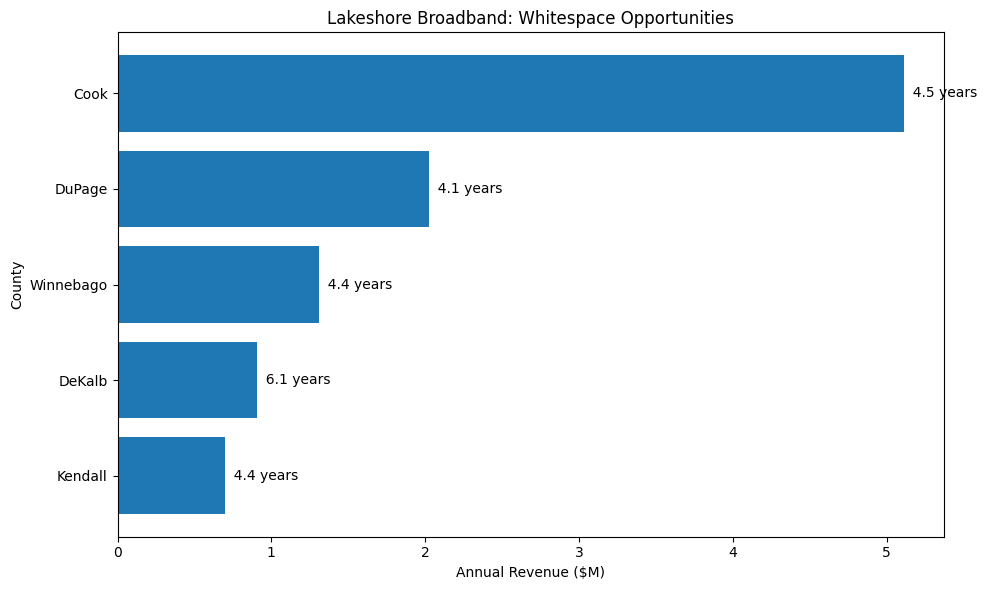

True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [88]:
import matplotlib.pyplot as plt

county["revenue_m"] = county["annual_revenue"] / 1_000_000

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(county["county_name"], county["revenue_m"])
ax.invert_yaxis()

for i, payback in enumerate(county["payback_years"]):
    ax.text(county["revenue_m"].iloc[i], i,
            f"  {payback:.1f} years", va="center")

ax.set_xlabel("Annual Revenue ($M)")
ax.set_ylabel("County")
ax.set_title("Lakeshore Broadband: Whitespace Opportunities")

plt.tight_layout()
plt.show()

assumptions = pd.DataFrame({
    "Assumption": [
        "Monthly ARPU",
        "Minimum Download Speed",
        "Minimum Upload Speed",
        "Maximum Competitors"
    ],
    "Value": [
        ARPU_MONTHLY,
        DOWN_MIN,
        UP_MIN,
        MAX_COMPETITORS
    ]
})
county_export = county.drop(columns=["revenue_m"]).copy()
county_export["avg_competitors"] = county_export["avg_competitors"].round(2)
county_export["payback_years"] = county_export["payback_years"].round(2)

with pd.ExcelWriter("lakeshore_whitespace.xlsx") as xw:
    county_export.to_excel(xw, sheet_name="County ranking", index=False)
    blk[blk["whitespace"]].to_excel(xw, sheet_name="Whitespace blocks",
                                    index=False)
    assumptions.to_excel(xw, sheet_name="Assumptions", index=False)
import os

print(os.path.exists("lakeshore_whitespace.xlsx"))

from google.colab import files

files.download("lakeshore_whitespace.xlsx")

## Individual check-out (5 min)
Answer in a sentence each, in the cell below:
1. Which county has the largest revenue opportunity, and which has the best payback? Are they the same? Why not?
2. What would this analysis have looked like in Excel? Name the specific step that breaks first.

## Part 2 — group extension (25 min, with your table of 3–4)
Hard switch when the clock says so, wherever you are: start from the table's most complete notebook — an unfinished Part 1 is normal.
1. **Sensitivity.** Loop over `ARPU_MONTHLY in (60, 75, 90)` and `MAX_COMPETITORS in (0, 1, 2)` and build a 3×3 table of total payback years. (Hint: wrap steps 5–6 in a function `run(arpu, max_comp)`.)
2. **Definition risk.** Re-run with satellite *included* in the competition count. How many whitespace blocks disappear? Would you show the partner both numbers?
3. **Recommendation.** Pick a top-2 county expansion plan and write three bullets defending it, including one risk you cannot see in this data (hint: the data says nothing about *who owns the poles*).

Largest Revenue Opporuntity is the Cook County, with Annual Revenue to be $5.1million dollars, but DuPage county has the best payback of a 4.07 years payback period, they are not the same because payback depends on the CAPEX as well.

You would clean the raw data in excel first by removing duplicates and standardize names, after that you calculate competition, revenue, and payback period. This might break when you clean and merge your data, wrong provider names can lead to wrong competitors counts and inaccurate revenue estimates.

In [94]:
def run(arpu, max_comp):
    ws = blk[
        (~blk["in_footprint"]) &
        (blk["avg_competitors"] <= max_comp) &
        (blk["relation_to_footprint"] == "adjacent")
    ].copy()

    ws["annual_revenue"] = (
        ws["units"] * ws["target_pen"] * arpu * 12
    )

    total_capex = ws["capex"].sum()
    total_revenue = ws["annual_revenue"].sum()

    if total_revenue == 0:
        return float("nan")

    return total_capex / total_revenue

results = []

for arpu in (60, 75, 90):
    row = []
    for max_comp in (0, 1, 2):
        row.append(run(arpu, max_comp))
    results.append(row)

sensitivity = pd.DataFrame(
    results,
    index=[60, 75, 90],
    columns=[0, 1, 2]
)

print(sensitivity.round(2))


terr = res[
    (~res["technology"].isin(SATELLITE)) &
    (res["low_latency"] == 1)
]

# Step 1: Include satellite offers
terr_satellite = res.copy()

served_satellite = terr_satellite[
    (terr_satellite["max_advertised_download_speed"] >= DOWN_MIN) &
    (terr_satellite["max_advertised_upload_speed"] >= UP_MIN)
]

# Step 2: Count providers at each location
loc_satellite = served_satellite.groupby("location_id").agg(
    n_providers=("provider_id", "nunique"),
    our_brand_present=("brand_name", lambda s: (s == OUR_BRAND).any())
).reset_index()

loc_satellite = locs.merge(
    loc_satellite, on="location_id", how="left"
)

loc_satellite["n_providers"] = (
    loc_satellite["n_providers"].fillna(0).astype(int)
)
loc_satellite["our_brand_present"] = (
    loc_satellite["our_brand_present"]
    .astype("boolean")
    .fillna(False)
)

loc_satellite["n_competitors"] = (
    loc_satellite["n_providers"] -
    loc_satellite["our_brand_present"].astype(int)
)

# Step 3: Recalculate competition at block level
blk_satellite = loc_satellite.groupby(
    ["block_geoid", "county_fips", "county_name"]
).agg(
    avg_competitors=("n_competitors", "mean")
).reset_index()

blk_satellite["in_footprint"] = (
    blk_satellite["block_geoid"].isin(footprint["block_geoid"])
)

blk_satellite = blk_satellite.merge(
    demo[["county_fips", "relation_to_footprint"]],
    on="county_fips",
    how="left"
)

# Step 4: Recalculate whitespace
blk_satellite["whitespace"] = (
    (~blk_satellite["in_footprint"]) &
    (blk_satellite["avg_competitors"] <= MAX_COMPETITORS) &
    (blk_satellite["relation_to_footprint"] == "adjacent")
)

# Step 5: Compare the results
original_count = blk["whitespace"].sum()
new_count = blk_satellite["whitespace"].sum()

print("Original whitespace blocks:", original_count)
print("With satellite competition:", new_count)
print("Blocks lost:", original_count - new_count)

Cook County and DuPage County
Cook County: highest projected annual revenue, then its DuPage County
Packback period: Dupage payback is at 4.07 years while Cook County is 4.55

       0     1     2
60  5.79  5.71  5.68
75  4.63  4.57  4.55
90  3.86  3.81  3.79
Original whitespace blocks: 458
With satellite competition: 131
Blocks lost: 327


_group answers here_